# 14 · Linear Algebra & Calculus for ML — Made Visual

Two branches of maths do almost all the work inside ML:
- **Linear algebra** is how models **compute**: data is a matrix, a layer is a matrix multiply, PCA is an eigen-decomposition, embeddings are vectors compared with dot products.
- **Calculus** is how models **learn**: the gradient says which way to change every weight, the chain rule (backprop) computes it, and the shape of the loss surface decides how hard training is.

This notebook builds intuition with pictures first, then code. You've already *used* most of these ideas in notebooks 01–07; here they get their own spotlight.

**Part A — Linear algebra:** vectors, norms, dot products and cosine similarity · matrices as transformations · solving linear systems · determinants · eigenvectors · SVD and low-rank compression

**Part B — Calculus:** derivatives · gradients · the chain rule · Jacobians and Hessians · Taylor approximations · convexity and saddle points · how curvature controls gradient descent · Newton's method · constrained optimisation (Lagrange multipliers)

As always: 🐍 pure Python → 🔢 NumPy → 📦 a library (NumPy's `linalg`, SymPy, PyTorch autograd).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0)

---
# Part A — Linear Algebra

## A1. Vectors

A **vector** is a list of numbers. In ML it's usually **one data point** (a customer's features) or **one set of weights**. Geometrically it's an arrow from the origin.

- Add: $\mathbf{a} + \mathbf{b}$ (tip to tail). Scale: $c\,\mathbf{a}$ (stretch).
- **Norm** = length. **L2** (Euclidean): $\|\mathbf{a}\|_2 = \sqrt{\sum a_i^2}$. **L1** (Manhattan): $\|\mathbf{a}\|_1 = \sum |a_i|$. (Ridge penalises L2², Lasso penalises L1 — notebook 01.)

‖a‖₂ = 3.1623 (NumPy 3.1623)   ‖a‖₁ = 4.0 (NumPy 4.0)


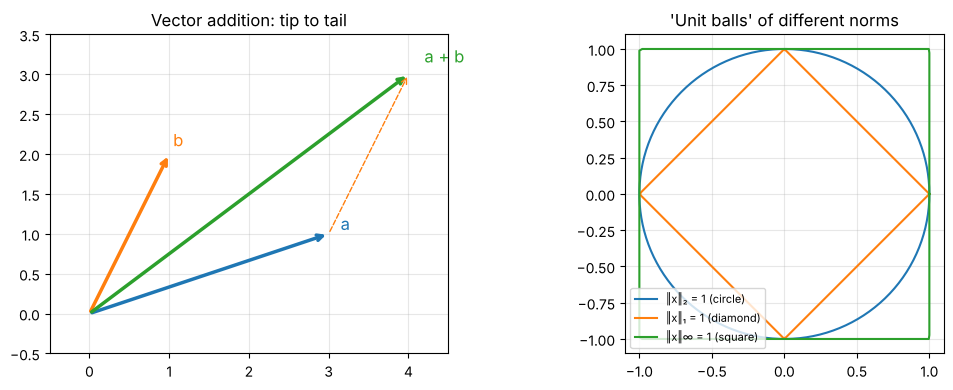

In [2]:
a, b = np.array([3.0, 1.0]), np.array([1.0, 2.0])

# 🐍 Pure Python norms
def l2_python(v): return math.sqrt(sum(x * x for x in v))
def l1_python(v): return sum(abs(x) for x in v)
print(f"‖a‖₂ = {l2_python(a):.4f} (NumPy {np.linalg.norm(a):.4f})   ‖a‖₁ = {l1_python(a)} (NumPy {np.linalg.norm(a, 1)})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for v, c, lbl in [(a, "C0", "a"), (b, "C1", "b"), (a + b, "C2", "a + b")]:
    ax[0].annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2.5)); ax[0].text(*(v * 1.05), lbl, color=c, fontsize=12)
ax[0].annotate("", xy=a + b, xytext=a, arrowprops=dict(arrowstyle="->", color="C1", lw=1, ls="--"))
ax[0].set_xlim(-0.5, 4.5); ax[0].set_ylim(-0.5, 3.5); ax[0].set_aspect("equal"); ax[0].set_title("Vector addition: tip to tail")
th = np.linspace(0, 2 * np.pi, 400); circle = np.c_[np.cos(th), np.sin(th)]
ax[1].plot(*circle.T, label="‖x‖₂ = 1 (circle)")
ax[1].plot(*(circle / np.abs(circle).sum(1, keepdims=True)).T, label="‖x‖₁ = 1 (diamond)")
ax[1].plot(*(circle / np.abs(circle).max(1, keepdims=True)).T, label="‖x‖∞ = 1 (square)")
ax[1].set_aspect("equal"); ax[1].legend(fontsize=8, loc="lower left"); ax[1].set_title("'Unit balls' of different norms")
plt.tight_layout(); plt.show()

The diamond's sharp corners sit **on the axes** — that's the geometric reason Lasso (L1) drives weights to exactly zero: the optimum tends to land on a corner, where some coordinates are 0.

### The dot product and cosine similarity
$$ \mathbf{a}\cdot\mathbf{b} = \sum_i a_i b_i = \|\mathbf{a}\|\,\|\mathbf{b}\|\cos\theta $$
It measures how much two vectors **point the same way**. Dividing out the lengths gives **cosine similarity** ∈ [−1, 1] — the standard way to compare embeddings (words, documents, users, images) in search and recommendation.

The **projection** of **b** onto **a** — the "shadow" of b along a — is $\frac{\mathbf{a}\cdot\mathbf{b}}{\mathbf{a}\cdot\mathbf{a}}\,\mathbf{a}$. Least-squares regression is a projection of y onto the space spanned by the feature columns.

In [3]:
# 🐍 / 🔢 / 📦 cosine similarity
def cosine_python(u, v):
    dot = sum(x * y for x, y in zip(u, v))
    return dot / (math.sqrt(sum(x * x for x in u)) * math.sqrt(sum(y * y for y in v)))

from sklearn.metrics.pairwise import cosine_similarity
print(f"pure Python {cosine_python(a, b):.4f} | NumPy {a @ b / (np.linalg.norm(a) * np.linalg.norm(b)):.4f} | sklearn {cosine_similarity([a], [b])[0, 0]:.4f}")

# Toy "word embeddings": similar meanings → similar directions
# dimensions (made up for illustration): [royalty, is-a-person, female]
emb = {"king": [0.95, 0.7, 0.05], "queen": [0.95, 0.7, 0.95], "man": [0.05, 0.9, 0.05], "woman": [0.05, 0.9, 0.95], "apple": [0.02, 0.02, 0.1]}
words = list(emb); M = np.array([emb[w] for w in words])
sim = cosine_similarity(M)
print("most similar to 'king':", sorted(((round(float(sim[0, j]), 3), w) for j, w in enumerate(words) if j), reverse=True)[:2])
analogy = M[0] - M[2] + M[3]                       # king − man + woman
print("king − man + woman is closest to:", words[int(np.argmax(cosine_similarity([analogy], M)[0] * (np.arange(5) != 0)))])

pure Python 0.7071 | NumPy 0.7071 | sklearn 0.7071
most similar to 'king': [(0.805, 'queen'), (0.638, 'man')]
king − man + woman is closest to: queen


## A2. Matrices — tables of data, and transformations

A matrix is two things at once:
1. **A dataset:** n rows (samples) × d columns (features). Predictions for all samples at once: $X\mathbf{w}$.
2. **A transformation:** multiplying a vector by a matrix **moves** it. Every matrix rotates, stretches, shears or flattens space. Each column of the matrix tells you where the corresponding basis vector ($\mathbf{e}_1 = (1,0)$, $\mathbf{e}_2 = (0,1)$) lands.

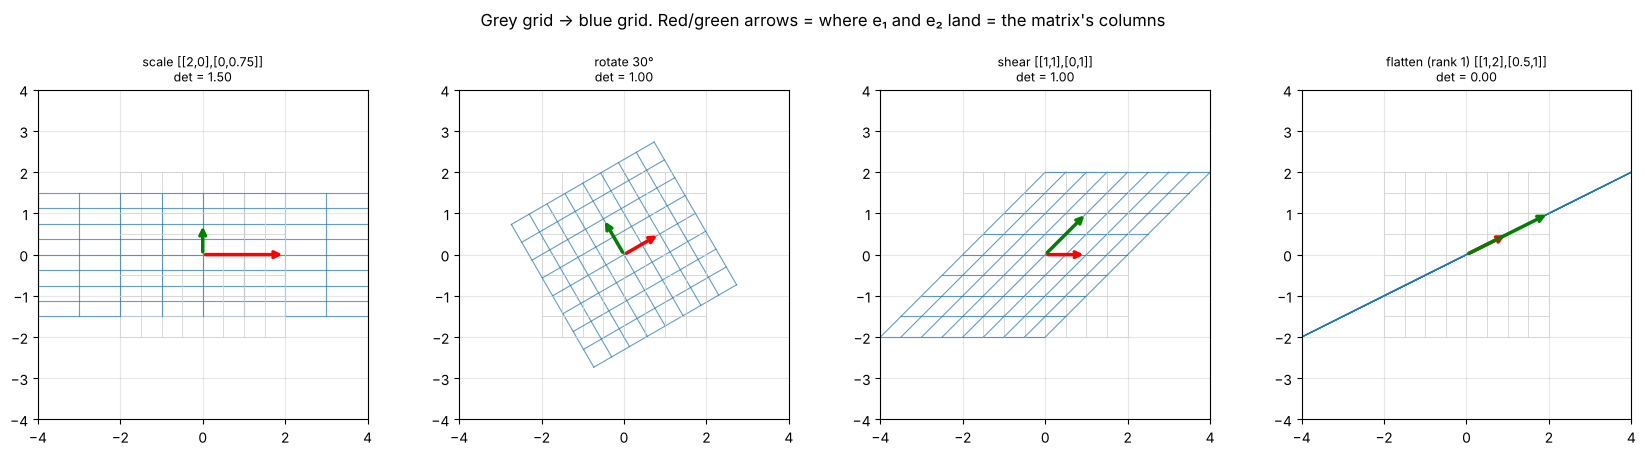

In [4]:
def show_transform(ax, A, title):
    g = np.linspace(-2, 2, 9)
    for v in g:                                        # draw a grid, then its image under A
        line1 = np.c_[np.full(50, v), np.linspace(-2, 2, 50)]; line2 = line1[:, ::-1]
        for L in (line1, line2):
            ax.plot(*L.T, c="lightgray", lw=0.6); ax.plot(*(L @ A.T).T, c="C0", lw=0.8, alpha=0.7)
    for col, c in zip(A.T, ["r", "g"]):
        ax.annotate("", xy=col, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2.5))
    ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.set_title(title, fontsize=9)

theta = np.pi / 6
mats = {"scale [[2,0],[0,0.75]]": np.array([[2, 0], [0, 0.75]]),
        "rotate 30°": np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]]),
        "shear [[1,1],[0,1]]": np.array([[1, 1], [0, 1]]),
        "flatten (rank 1) [[1,2],[0.5,1]]": np.array([[1, 2], [0.5, 1]])}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, (t, A) in zip(axes, mats.items()):
    show_transform(ax, A, t + f"\ndet = {np.linalg.det(A):.2f}")
plt.suptitle("Grey grid → blue grid. Red/green arrows = where e₁ and e₂ land = the matrix's columns", y=1.03); plt.tight_layout(); plt.show()

The **determinant** is the factor by which a matrix scales **area** (volume in higher dimensions). det = 0 means space is squashed flat — information is lost and the transformation **can't be undone** (the matrix has no inverse). Negative det = orientation flipped.

### Matrix multiplication = doing transformations in sequence
$(AB)\mathbf{x} = A(B\mathbf{x})$: first B, then A. Order matters ($AB \ne BA$ in general). Shapes must line up: $(n \times k)(k \times m) \to (n \times m)$. A neural network layer is exactly this: $\text{activation}(XW + b)$.

In [5]:
# 🐍 Pure Python matrix multiply — the triple loop
def matmul_python(A, B):
    n, k, m = len(A), len(B), len(B[0])
    assert len(A[0]) == k, "inner dimensions must match"
    return [[sum(A[i][p] * B[p][j] for p in range(k)) for j in range(m)] for i in range(n)]

A = rng.normal(size=(3, 4)); B = rng.normal(size=(4, 2))
print("pure Python == NumPy:", np.allclose(matmul_python(A.tolist(), B.tolist()), A @ B))
R, S = mats["rotate 30°"], mats["scale [[2,0],[0,0.75]]"]
print("rotate-then-scale == scale-then-rotate?", np.allclose(S @ R, R @ S))

import time
X_big = rng.normal(size=(300, 300))
t0 = time.perf_counter(); matmul_python(X_big.tolist(), X_big.tolist()); t_py = time.perf_counter() - t0
t0 = time.perf_counter(); X_big @ X_big; t_np = time.perf_counter() - t0
print(f"300×300 matmul: pure Python {t_py:.2f}s, NumPy {t_np * 1000:.2f}ms → ~{t_py / t_np:,.0f}× faster (BLAS + vectorisation)")

pure Python == NumPy: True
rotate-then-scale == scale-then-rotate? False


300×300 matmul: pure Python 1.40s, NumPy 1.79ms → ~783× faster (BLAS + vectorisation)


## A3. Solving linear systems

$A\mathbf{x} = \mathbf{b}$: "which input **x** does A map to **b**?" — e.g. the normal equation $(X^\top X)\mathbf{w} = X^\top\mathbf{y}$ from linear regression.

**Gaussian elimination:** use row operations to make A upper-triangular, then solve from the bottom up. Swap rows so the largest available number is the pivot (**partial pivoting**) — it avoids dividing by tiny numbers.

In [6]:
# 🐍 Pure Python Gaussian elimination with partial pivoting
def solve_python(A, b):
    n = len(A); M = [row[:] + [bi] for row, bi in zip(A, b)]           # augmented matrix [A | b]
    for col in range(n):
        piv = max(range(col, n), key=lambda r: abs(M[r][col]))          # partial pivoting
        if abs(M[piv][col]) < 1e-12: raise ValueError("matrix is singular")
        M[col], M[piv] = M[piv], M[col]
        for r in range(col + 1, n):                                     # eliminate below the pivot
            f = M[r][col] / M[col][col]
            M[r] = [x - f * y for x, y in zip(M[r], M[col])]
    x = [0.0] * n
    for i in reversed(range(n)):                                        # back substitution
        x[i] = (M[i][n] - sum(M[i][j] * x[j] for j in range(i + 1, n))) / M[i][i]
    return x

A3 = [[2, 1, -1], [-3, -1, 2], [-2, 1, 2]]; b3 = [8, -11, -3]
print("pure Python:", np.round(solve_python(A3, b3), 6), "| np.linalg.solve:", np.linalg.solve(A3, b3))

pure Python: [ 2.  3. -1.] | np.linalg.solve: [ 2.  3. -1.]


**Never compute an inverse to solve a system.** `np.linalg.solve` (an LU factorisation) is faster and more accurate than `np.linalg.inv(A) @ b`.

**When does it fail?** When columns are **linearly dependent** — one is a combination of others — so A is singular (rank-deficient). In ML that's **perfect multicollinearity**: e.g. including both "price in dollars" and "price in cents". Nearly dependent columns make A **ill-conditioned**: tiny changes in the data cause huge changes in the solution. The **condition number** measures this.

In [7]:
X_ok = rng.normal(size=(100, 3))
X_bad = X_ok.copy(); X_bad[:, 2] = X_bad[:, 0] + X_bad[:, 1] + rng.normal(0, 1e-6, 100)   # almost a combination
for name, Xm in [("independent features", X_ok), ("nearly dependent features", X_bad)]:
    print(f"{name:26s} rank {np.linalg.matrix_rank(Xm, tol=1e-4)} | condition number of XᵀX = {np.linalg.cond(Xm.T @ Xm):.2e}")

y_ = X_bad[:, 0] + 2 * X_bad[:, 1] + rng.normal(0, 0.1, 100)       # the truth uses only the first two columns
for trial in range(3):
    y_noisy = y_ + rng.normal(0, 0.01, 100)                              # a tiny change to y
    w = np.linalg.lstsq(X_bad, y_noisy, rcond=None)[0]
    print(f"   fitted weights on nearly-dependent data, trial {trial + 1}: {w.round(1)}")
print("→ the weights swing wildly. Ridge regression (adding λI to XᵀX) fixes the conditioning.")

independent features       rank 3 | condition number of XᵀX = 1.35e+00
nearly dependent features  rank 2 | condition number of XᵀX = 1.07e+13
   fitted weights on nearly-dependent data, trial 1: [-20725.6 -20724.6  20726.6]
   fitted weights on nearly-dependent data, trial 2: [-22387.9 -22386.9  22388.9]
   fitted weights on nearly-dependent data, trial 3: [-22623.3 -22622.3  22624.3]
→ the weights swing wildly. Ridge regression (adding λI to XᵀX) fixes the conditioning.


## A4. Eigenvectors and eigenvalues

Most vectors change **direction** when a matrix acts on them. **Eigenvectors** are the special directions that only get **stretched**:
$$ A\mathbf{v} = \lambda\mathbf{v} $$
λ (the eigenvalue) is the stretch factor. For a symmetric matrix (like a covariance matrix) the eigenvectors are perpendicular, and they're the matrix's natural axes.

Where they appear in ML: **PCA** (eigenvectors of the covariance matrix, notebook 06), **PageRank** and Markov-chain steady states (eigenvector with λ = 1), the **curvature** of a loss surface (eigenvalues of the Hessian, Part B), spectral clustering, and stability of RNNs.

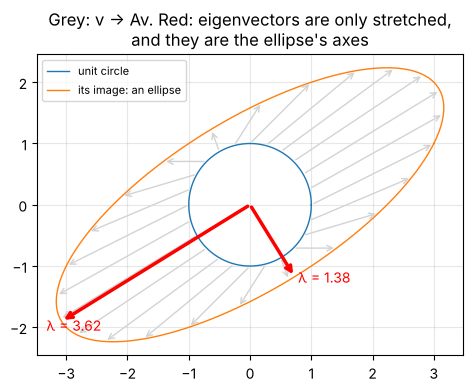

In [8]:
A_sym = np.array([[3.0, 1.0], [1.0, 2.0]])
vals, vecs = np.linalg.eigh(A_sym)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for ang in np.linspace(0, 2 * np.pi, 24, endpoint=False):
    v = np.array([np.cos(ang), np.sin(ang)]); Av = A_sym @ v
    ax.annotate("", xy=Av, xytext=v, arrowprops=dict(arrowstyle="->", color="lightgray"))
for lam, v in zip(vals, vecs.T):
    ax.annotate("", xy=lam * v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="r", lw=2.5))
    ax.text(*(lam * v * 1.08), f"λ = {lam:.2f}", color="r")
ax.plot(*np.c_[np.cos(th), np.sin(th)].T, c="C0", lw=1, label="unit circle")
ax.plot(*(np.c_[np.cos(th), np.sin(th)] @ A_sym.T).T, c="C1", lw=1, label="its image: an ellipse")
ax.set_aspect("equal"); ax.legend(fontsize=8); ax.set_title("Grey: v → Av. Red: eigenvectors are only stretched,\nand they are the ellipse's axes"); plt.show()

In [9]:
# 🐍 Pure Python power iteration (largest eigenvalue) — the algorithm behind PageRank
def power_iteration_python(A, iters=100):
    v = [1.0] * len(A)
    for _ in range(iters):
        w = [sum(A[i][j] * v[j] for j in range(len(v))) for i in range(len(v))]
        norm = math.sqrt(sum(x * x for x in w)); v = [x / norm for x in w]
    lam = sum(v[i] * sum(A[i][j] * v[j] for j in range(len(v))) for i in range(len(v)))
    return lam, v

lam, v = power_iteration_python(A_sym.tolist())
print(f"pure Python power iteration: λ = {lam:.4f}, v = {np.round(v, 4)}")
print(f"np.linalg.eigh:              λ = {vals[-1]:.4f}, v = {vecs[:, -1].round(4)}  (sign is arbitrary)")

# A tiny PageRank: 4 web pages; P[i, j] = probability of clicking from page j to page i
P = np.array([[0, 0, 1, 0.5], [1 / 3, 0, 0, 0], [1 / 3, 0.5, 0, 0.5], [1 / 3, 0.5, 0, 0]])
d = 0.85; G = d * P + (1 - d) / 4                                    # damping: sometimes jump to a random page
w_, V_ = np.linalg.eig(G); rank = np.real(V_[:, np.argmin(np.abs(w_ - 1))]); rank /= rank.sum()
print("PageRank (eigenvector with λ = 1):", rank.round(3))

pure Python power iteration: λ = 3.6180, v = [0.8507 0.5257]
np.linalg.eigh:              λ = 3.6180, v = [-0.8507 -0.5257]  (sign is arbitrary)
PageRank (eigenvector with λ = 1): [0.368 0.142 0.288 0.202]


## A5. The Singular Value Decomposition (SVD)

**Every** matrix — any shape — can be written as
$$ A = U\,\Sigma\,V^\top $$
**rotate** ($V^\top$) → **stretch** along the axes by the singular values ($\Sigma$, sorted largest first) → **rotate** ($U$). It's the most useful decomposition in ML: PCA, least squares via the pseudo-inverse, recommender systems (matrix factorisation), latent semantic analysis, and compression.

**Eckart–Young theorem:** keeping only the top k singular values gives the **best possible rank-k approximation** of A. If the singular values drop fast, a few components capture almost everything.

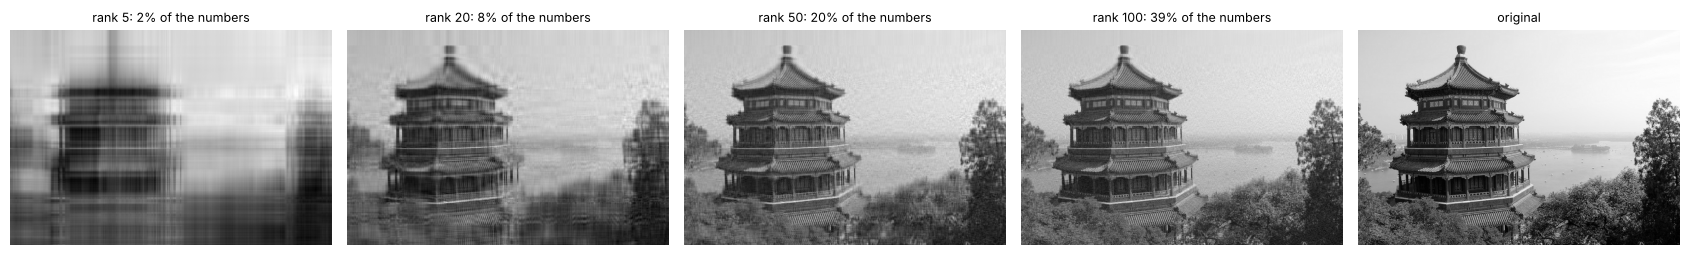

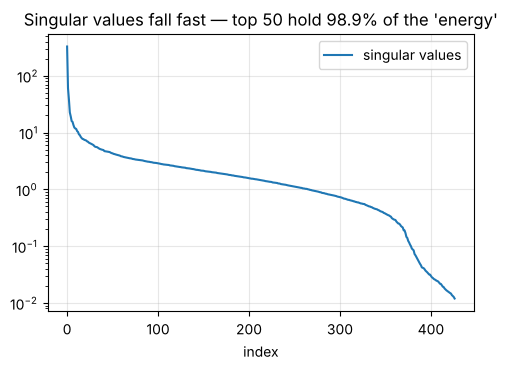

In [10]:
from sklearn.datasets import load_sample_image
img = load_sample_image("china.jpg").mean(axis=2) / 255.0          # grayscale, 427 × 640
U, S, Vt = np.linalg.svd(img, full_matrices=False)

fig, axes = plt.subplots(1, 5, figsize=(17, 3))
for ax, k in zip(axes, [5, 20, 50, 100, None]):
    approx = img if k is None else (U[:, :k] * S[:k]) @ Vt[:k]
    stored = img.size if k is None else k * (U.shape[0] + Vt.shape[1] + 1)
    ax.imshow(approx, cmap="gray"); ax.axis("off")
    ax.set_title("original" if k is None else f"rank {k}: {stored / img.size:.0%} of the numbers", fontsize=9)
plt.tight_layout(); plt.show()

energy = np.cumsum(S ** 2) / np.sum(S ** 2)
plt.semilogy(S, label="singular values"); plt.xlabel("index"); plt.title(f"Singular values fall fast — top 50 hold {energy[49]:.1%} of the 'energy'"); plt.legend(); plt.show()

In [11]:
# Check the decomposition and the rank-k error formula (Frobenius error² = sum of the dropped σ²)
print("U Σ Vᵀ reconstructs the image:", np.allclose((U * S) @ Vt, img))
k = 50; approx = (U[:, :k] * S[:k]) @ Vt[:k]
print(f"rank-{k} error: computed {np.linalg.norm(img - approx):.4f} vs theory √Σσ²(dropped) = {np.sqrt(np.sum(S[k:] ** 2)):.4f}")
print("U and V have orthonormal columns:", np.allclose(U.T @ U, np.eye(U.shape[1])), np.allclose(Vt @ Vt.T, np.eye(Vt.shape[0])))

U Σ Vᵀ reconstructs the image: True
rank-50 error: computed 35.1670 vs theory √Σσ²(dropped) = 35.1670
U and V have orthonormal columns: True True


---
# Part B — Calculus

## B1. The derivative — slope at a point

$$ f'(x) = \lim_{h\to 0}\frac{f(x+h) - f(x)}{h} $$
The derivative tells you how fast f changes as x changes — the slope of the tangent line. For training: **how much the loss changes if I nudge this weight.** Rules you'll meet: $(x^n)' = nx^{n-1}$, $(e^x)' = e^x$, $(\ln x)' = 1/x$, $\sigma'(x) = \sigma(x)(1-\sigma(x))$.

Three ways to get a derivative:
- 🐍 **Numerical** (finite differences) — needs only f; approximate; 2 evaluations per input.
- 📦 **Symbolic** (SymPy) — exact formula; can blow up in size for complex functions.
- 📦 **Automatic differentiation** (PyTorch) — exact *values*, efficient; what deep learning uses (notebook 07).

SymPy derivative: 3*x**2 + 3*cos(3*x) - 2


at x = 1.2 → numerical -0.370275 | symbolic -0.370275 | autograd -0.370275


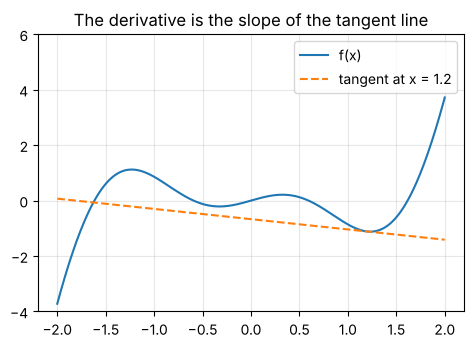

In [12]:
f = lambda x: x ** 3 - 2 * x + math.sin(3 * x)
def derivative_python(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)            # central difference: error ∝ h², much better than (f(x+h)−f(x))/h

import sympy as sp
xs_ = sp.symbols("x"); f_sym = xs_ ** 3 - 2 * xs_ + sp.sin(3 * xs_)
f_prime = sp.diff(f_sym, xs_); print("SymPy derivative:", f_prime)

import torch
xt = torch.tensor(1.2, requires_grad=True)
(xt ** 3 - 2 * xt + torch.sin(3 * xt)).backward()
print(f"at x = 1.2 → numerical {derivative_python(f, 1.2):.6f} | symbolic {float(f_prime.subs(xs_, 1.2)):.6f} | autograd {xt.grad.item():.6f}")

x0 = 1.2; grid = np.linspace(-2, 2, 300)
plt.plot(grid, [f(g) for g in grid], label="f(x)")
plt.plot(grid, f(x0) + derivative_python(f, x0) * (grid - x0), "--", label="tangent at x = 1.2")
plt.ylim(-4, 6); plt.legend(); plt.title("The derivative is the slope of the tangent line"); plt.show()

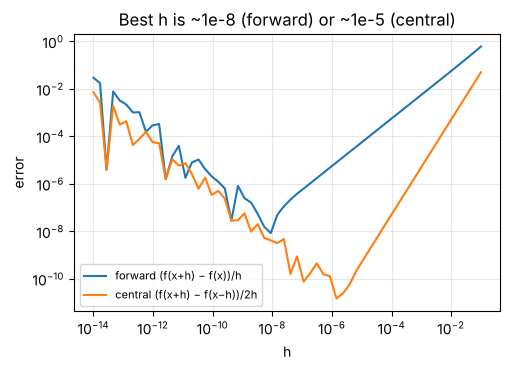

In [13]:
# Finite-difference step size: too big → approximation error; too small → floating-point round-off error
true = float(f_prime.subs(xs_, 1.2)); hs = np.logspace(-14, -1, 60)
plt.loglog(hs, [abs((f(1.2 + h) - f(1.2)) / h - true) for h in hs], label="forward (f(x+h) − f(x))/h")
plt.loglog(hs, [abs(derivative_python(f, 1.2, h) - true) for h in hs], label="central (f(x+h) − f(x−h))/2h")
plt.xlabel("h"); plt.ylabel("error"); plt.legend(fontsize=8); plt.title("Best h is ~1e-8 (forward) or ~1e-5 (central)"); plt.show()

## B2. Gradients — derivatives in many dimensions

A loss depends on many weights. The **partial derivative** $\partial f/\partial w_i$ is the slope when only $w_i$ moves. Stacking them gives the **gradient**:
$$ \nabla f = \left(\frac{\partial f}{\partial w_1}, \dots, \frac{\partial f}{\partial w_d}\right) $$
Key fact: **the gradient points in the direction of steepest increase**, and it's perpendicular to the contour lines. So $-\nabla f$ is the steepest way down — that's gradient descent.

numerical: [ 1.4 -1.2] | analytic: [1.4, -1.2]


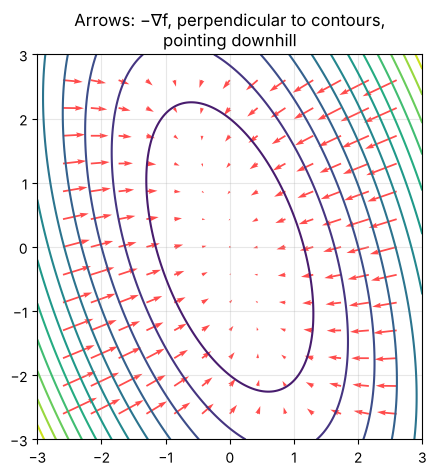

In [14]:
def loss2d(w):       # a bowl, longer in one direction
    return 0.5 * (3 * w[0] ** 2 + w[1] ** 2) + 0.8 * w[0] * w[1]

# 🐍 numerical gradient (works for any function of a list of numbers)
def grad_python(f, w, h=1e-5):
    g = []
    for i in range(len(w)):
        up = list(w); dn = list(w); up[i] += h; dn[i] -= h
        g.append((f(up) - f(dn)) / (2 * h))
    return g

# analytic gradient: ∂/∂w0 = 3w0 + 0.8w1, ∂/∂w1 = w1 + 0.8w0
print("numerical:", np.round(grad_python(loss2d, [1.0, -2.0]), 5), "| analytic:", [3 * 1 + 0.8 * -2, -2 + 0.8 * 1])

W0, W1 = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200)); Z = loss2d([W0, W1])
q0, q1 = np.meshgrid(np.linspace(-2.6, 2.6, 13), np.linspace(-2.6, 2.6, 13))
plt.figure(figsize=(5.5, 5)); plt.contour(W0, W1, Z, levels=15, cmap="viridis")
plt.quiver(q0, q1, -(3 * q0 + 0.8 * q1), -(q1 + 0.8 * q0), color="r", alpha=0.7)
plt.gca().set_aspect("equal"); plt.title("Arrows: −∇f, perpendicular to contours,\npointing downhill"); plt.show()

## B3. The chain rule — the engine of backpropagation

If $y = f(g(x))$, then $\frac{dy}{dx} = f'(g(x)) \cdot g'(x)$: **multiply the local slopes along the path.** With many variables, add up the contributions from every path.

A neural network is a long chain of simple functions, so the gradient of the loss with respect to any weight is a product of local derivatives — computed efficiently backwards from the loss (**reverse-mode autodiff** = backprop, notebook 07). Reverse mode costs about one extra forward pass no matter how many weights there are; that's why it's used for training (many inputs, one scalar loss).

In [15]:
# Example: one logistic neuron. L = −[y log σ(wx+b) + (1−y) log(1−σ(wx+b))]
w_, b_, x_, y_t = 0.7, -0.2, 2.0, 1.0
sig = lambda z: 1 / (1 + math.exp(-z))

# 🐍 by hand with the chain rule: dL/dw = dL/dp · dp/dz · dz/dw
z = w_ * x_ + b_; p = sig(z)
dL_dp = -(y_t / p) + (1 - y_t) / (1 - p)
dp_dz = p * (1 - p)
dz_dw = x_
print(f"chain rule: {dL_dp:.4f} × {dp_dz:.4f} × {dz_dw} = {dL_dp * dp_dz * dz_dw:.6f}   (simplifies to (p − y)·x = {(p - y_t) * x_:.6f})")

# 📦 PyTorch autograd
wt = torch.tensor(w_, requires_grad=True); bt = torch.tensor(b_, requires_grad=True)
pt = torch.sigmoid(wt * x_ + bt); Lt = -(y_t * torch.log(pt) + (1 - y_t) * torch.log(1 - pt)); Lt.backward()
print(f"autograd:   dL/dw = {wt.grad.item():.6f}, dL/db = {bt.grad.item():.6f}")
print(f"numerical:  dL/dw = {derivative_python(lambda w: -(math.log(sig(w * x_ + b_))), w_):.6f}")

chain rule: -1.3012 × 0.1779 × 2.0 = -0.462950   (simplifies to (p − y)·x = -0.462950)
autograd:   dL/dw = -0.462950, dL/db = -0.231475
numerical:  dL/dw = -0.462950


## B4. Jacobians and Hessians

- **Jacobian** $J$: for a function with vector output $\mathbf{f}: \mathbb{R}^n \to \mathbb{R}^m$, the m × n matrix of all partial derivatives $J_{ij} = \partial f_i / \partial x_j$. Backprop multiplies Jacobians along the chain (e.g. softmax's Jacobian is $\text{diag}(p) - pp^\top$).
- **Hessian** $H$: the matrix of **second** derivatives of a scalar function, $H_{ij} = \partial^2 f / \partial x_i \partial x_j$. It describes **curvature**: its eigenvalues say how sharply the surface bends in each direction.

In [16]:
# 🔢 Numerical Jacobian of softmax vs the formula vs PyTorch
def softmax_np(z): e = np.exp(z - z.max()); return e / e.sum()
def jacobian_numpy(f, x, h=1e-6):
    J = np.zeros((len(f(x)), len(x)))
    for j in range(len(x)):
        e = np.zeros(len(x)); e[j] = h
        J[:, j] = (f(x + e) - f(x - e)) / (2 * h)
    return J

zv = np.array([1.0, 2.0, 0.5]); pv = softmax_np(zv)
J_formula = np.diag(pv) - np.outer(pv, pv)
J_torch = torch.autograd.functional.jacobian(lambda t: torch.softmax(t, 0), torch.tensor(zv)).numpy()
print("softmax Jacobian — numerical == formula == PyTorch:", np.allclose(jacobian_numpy(softmax_np, zv), J_formula, atol=1e-6), np.allclose(J_formula, J_torch))

# Hessian of loss2d: constant, because the loss is quadratic
H_torch = torch.autograd.functional.hessian(lambda w: 0.5 * (3 * w[0] ** 2 + w[1] ** 2) + 0.8 * w[0] * w[1], torch.tensor([1.0, -2.0])).numpy()
print("Hessian of loss2d:\n", H_torch, "\neigenvalues (curvatures):", np.linalg.eigvalsh(H_torch).round(3))

softmax Jacobian — numerical == formula == PyTorch: True True
Hessian of loss2d:
 [[3.  0.8]
 [0.8 1. ]] 
eigenvalues (curvatures): [0.719 3.281]


## B5. Taylor approximation — why gradient descent and Newton's method work

Near a point $x_0$, any smooth function looks like a polynomial:
$$ f(x) \approx f(x_0) + f'(x_0)(x - x_0) + \tfrac{1}{2}f''(x_0)(x - x_0)^2 $$
- **1st order (a line):** what gradient descent assumes. Trust it only for small steps → small learning rate.
- **2nd order (a parabola):** what Newton's method and XGBoost (notebook 11) use — jump straight to the parabola's minimum.

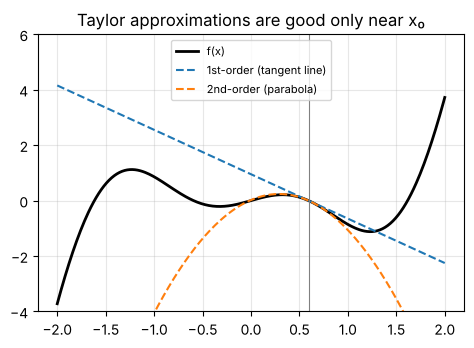

In [17]:
x0 = 0.6; d1 = derivative_python(f, x0); d2 = (f(x0 + 1e-4) - 2 * f(x0) + f(x0 - 1e-4)) / 1e-8
plt.plot(grid, [f(g) for g in grid], "k", lw=2, label="f(x)")
plt.plot(grid, f(x0) + d1 * (grid - x0), "--", label="1st-order (tangent line)")
plt.plot(grid, f(x0) + d1 * (grid - x0) + 0.5 * d2 * (grid - x0) ** 2, "--", label="2nd-order (parabola)")
plt.axvline(x0, c="gray", lw=0.8); plt.ylim(-4, 6); plt.legend(fontsize=8); plt.title("Taylor approximations are good only near x₀"); plt.show()

## B6. Convexity, local minima and saddle points

A function is **convex** if the line segment between any two points on its graph lies above the graph — a bowl. Convex losses have **one** minimum and gradient descent finds it: linear regression (MSE), logistic regression (log-loss), SVMs. A twice-differentiable function is convex exactly when its Hessian is positive semi-definite everywhere (all eigenvalues ≥ 0).

Neural-network losses are **non-convex**: many local minima and, in high dimensions, a huge number of **saddle points** — points where the gradient is zero but the surface goes up in some directions and down in others (Hessian eigenvalues of mixed sign). Noise from SGD and momentum help escape them.

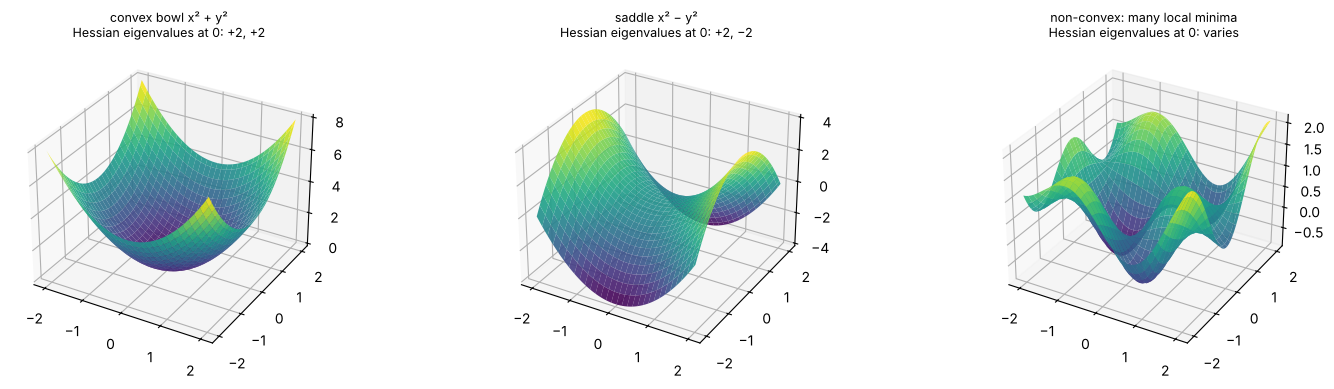

In [18]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
fig = plt.figure(figsize=(15, 4))
Xg, Yg = np.meshgrid(np.linspace(-2, 2, 60), np.linspace(-2, 2, 60))
for i, (name, Zg, eig) in enumerate([("convex bowl x² + y²", Xg**2 + Yg**2, "+2, +2"),
                                     ("saddle x² − y²", Xg**2 - Yg**2, "+2, −2"),
                                     ("non-convex: many local minima", np.sin(2 * Xg) * np.cos(2 * Yg) + 0.2 * (Xg**2 + Yg**2), "varies")]):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d"); ax.plot_surface(Xg, Yg, Zg, cmap="viridis", alpha=0.9)
    ax.set_title(f"{name}\nHessian eigenvalues at 0: {eig}", fontsize=9)
plt.tight_layout(); plt.show()

## B7. How curvature controls gradient descent

For a quadratic loss with Hessian H, gradient descent:
- **diverges** if the learning rate η > 2 / λ_max (it overshoots along the steepest direction),
- converges at a speed set by the **condition number** κ = λ_max / λ_min. Large κ = a long, narrow valley → **zig-zagging** and slow progress along the flat direction.

That's why **feature scaling** matters (notebook 01): unscaled features make κ huge. **Momentum** dampens the zig-zag; **Adam** rescales each direction; **Newton's method** uses $H^{-1}$ to undo the stretching and reaches a quadratic's minimum in **one step** — but forming and inverting H is too expensive for networks with millions of weights.

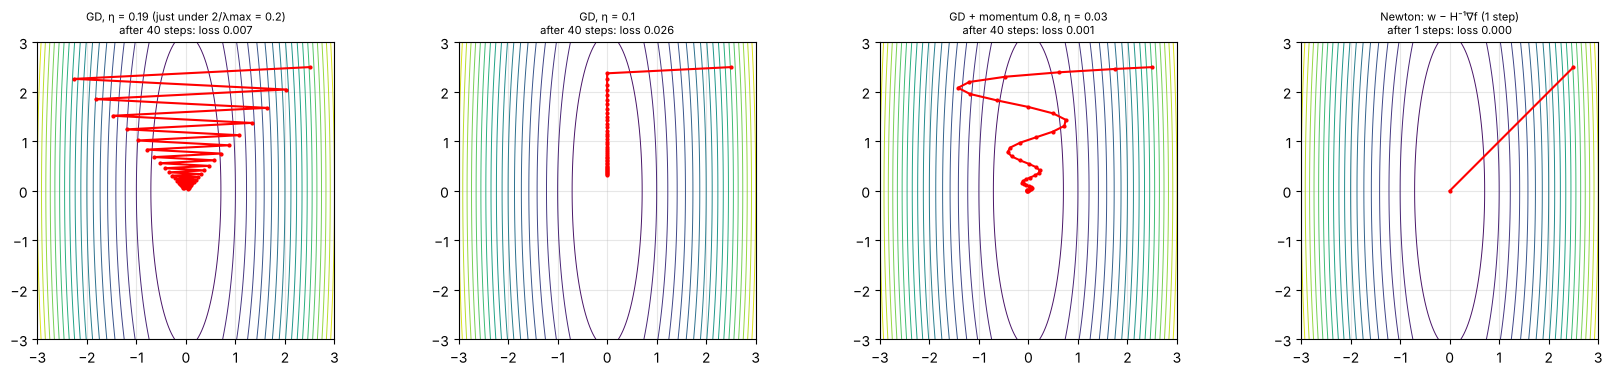

In [19]:
def run(H, step, w0=np.array([2.5, 2.5]), n=40, momentum=0.0):
    w, v, path = w0.copy(), np.zeros(2), [w0.copy()]
    for _ in range(n):
        g = H @ w
        v = momentum * v + g; w = w - step * v; path.append(w.copy())
    return np.array(path)

H_ill = np.array([[10.0, 0.0], [0.0, 0.5]])                 # κ = 20
lam_max = 10.0
Xg, Yg = np.meshgrid(np.linspace(-3, 3, 200), np.linspace(-3, 3, 200)); Zq = 0.5 * (10 * Xg**2 + 0.5 * Yg**2)
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
cases = [("GD, η = 0.19 (just under 2/λmax = 0.2)", run(H_ill, 0.19)), ("GD, η = 0.1", run(H_ill, 0.1)),
         ("GD + momentum 0.8, η = 0.03", run(H_ill, 0.03, momentum=0.8)),
         ("Newton: w − H⁻¹∇f (1 step)", np.array([[2.5, 2.5], np.array([2.5, 2.5]) - np.linalg.solve(H_ill, H_ill @ np.array([2.5, 2.5]))]))]
for ax, (name, path) in zip(axes, cases):
    ax.contour(Xg, Yg, Zq, levels=20, cmap="viridis", linewidths=0.7); ax.plot(*path.T, "r.-", ms=4)
    ax.set_title(f"{name}\nafter {len(path) - 1} steps: loss {0.5 * path[-1] @ H_ill @ path[-1]:.3f}", fontsize=8); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [20]:
# The divergence threshold, checked: η slightly above 2/λmax blows up
for eta in [0.19, 0.2, 0.21]:
    p_ = run(H_ill, eta, n=60)
    print(f"η = {eta}: final distance from the minimum {np.linalg.norm(p_[-1]):.3e}")

η = 0.19: final distance from the minimum 7.709e-03
η = 0.2: final distance from the minimum 2.500e+00
η = 0.21: final distance from the minimum 7.612e+02


## B8. Constrained optimisation — Lagrange multipliers

Sometimes we optimise **subject to a constraint**: maximise margin subject to classifying points correctly (SVM), maximise variance subject to a unit-length direction (PCA), maximise entropy subject to known averages.

**Idea:** at the constrained optimum, the objective's gradient must be **parallel** to the constraint's gradient — otherwise you could slide along the constraint and do better. So solve
$$ \nabla f = \lambda \nabla g, \qquad g(\mathbf{x}) = 0 $$
**Example (this is PCA!):** maximise $\mathbf{v}^\top C\mathbf{v}$ (variance along v) subject to $\mathbf{v}^\top\mathbf{v} = 1$. The condition $2C\mathbf{v} = 2\lambda\mathbf{v}$ says **v must be an eigenvector of C**, and the variance $\mathbf{v}^\top C\mathbf{v} = \lambda$ is largest for the top eigenvector.

brute force over unit vectors: best v = [0.906 0.423], variance 3.5620
top eigenvector of C:          v = [-0.906 -0.424], eigenvalue 3.5620  ← same (up to sign)


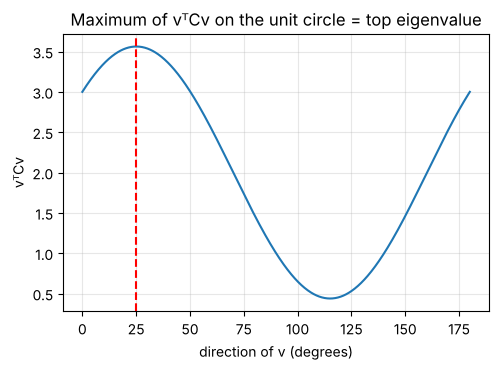

In [21]:
C = np.array([[3.0, 1.2], [1.2, 1.0]])
angles = np.linspace(0, np.pi, 721); V = np.c_[np.cos(angles), np.sin(angles)]   # every unit vector (half circle)
variance = np.einsum("ij,jk,ik->i", V, C, V)
best = V[np.argmax(variance)]
ev, evec = np.linalg.eigh(C)
print(f"brute force over unit vectors: best v = {best.round(3)}, variance {variance.max():.4f}")
print(f"top eigenvector of C:          v = {evec[:, -1].round(3)}, eigenvalue {ev[-1]:.4f}  ← same (up to sign)")

plt.plot(np.degrees(angles), variance); plt.axvline(np.degrees(angles[np.argmax(variance)]), ls="--", c="r")
plt.xlabel("direction of v (degrees)"); plt.ylabel("vᵀCv"); plt.title("Maximum of vᵀCv on the unit circle = top eigenvalue"); plt.show()

With **inequality** constraints ($g(\mathbf{x}) \le 0$), the conditions become the **KKT conditions**; they're how the SVM dual is derived and why only the support vectors have non-zero multipliers (notebook 04).

## Key takeaways
**Linear algebra**
- Vectors are data points/weights; dot product & cosine measure alignment; L1/L2 norms underpin regularisation.
- A matrix is a transformation; columns show where basis vectors go; det = area scaling; multiplication = composition.
- Solve systems with `solve`/`lstsq`, never `inv`; dependent features → singular/ill-conditioned → unstable weights.
- Eigenvectors are directions only stretched; SVD = rotate–stretch–rotate and gives the best low-rank approximation.

**Calculus**
- Derivative = slope; gradient = direction of steepest ascent; step along −gradient to learn.
- Chain rule = multiply local derivatives backwards → backprop; autodiff gives exact gradients cheaply.
- Hessian = curvature; its eigenvalues set the max learning rate (2/λmax) and the condition number (zig-zagging).
- Convex = one minimum; deep nets are non-convex with many saddle points.
- Lagrange multipliers: at a constrained optimum the gradients are parallel — PCA falls out as an eigenproblem.

## Exercises
1. Implement the **QR-free** least-squares solution via the SVD pseudo-inverse $w = V\Sigma^{-1}U^\top y$ and check it matches `np.linalg.lstsq` on the nearly-dependent `X_bad` (drop tiny singular values!).
2. Use `grad_python` + gradient descent to minimise the non-convex function $\sin(2x)\cos(2y) + 0.2(x^2 + y^2)$ from 5 random starting points. Do they all reach the same minimum?
3. Compute the Hessian of $f(x, y) = x^2 - y^2$ at the origin with `torch.autograd.functional.hessian`. How do its eigenvalues tell you it's a saddle?
4. Use the SVD to compress the image to rank 30 and compute the compression ratio and the relative error $\|A - A_k\| / \|A\|$.

In [22]:
# Exercise 1 — solution: pseudo-inverse via SVD, discarding near-zero singular values
U_, S_, Vt_ = np.linalg.svd(X_bad, full_matrices=False)
keep = S_ > 1e-3 * S_[0]
w_pinv = Vt_[keep].T @ ((U_[:, keep].T @ y_) / S_[keep])
print("singular values:", S_.round(6), "→ kept", keep.sum())
print("pseudo-inverse weights (minimum-norm, stable):", w_pinv.round(3))
print("Since column 3 ≈ column 1 + column 2, every w = (1−a, 2−a, a) fits equally well. The pseudo-inverse")
print("picks the one with the smallest norm (a = 1 → [0, 1, 1]) instead of the wild ±20,000 solutions above.")

singular values: [1.7202531e+01 1.0823309e+01 5.0000000e-06] → kept 2
pseudo-inverse weights (minimum-norm, stable): [1.000e-03 1.003e+00 1.004e+00]
Since column 3 ≈ column 1 + column 2, every w = (1−a, 2−a, a) fits equally well. The pseudo-inverse
picks the one with the smallest norm (a = 1 → [0, 1, 1]) instead of the wild ±20,000 solutions above.


In [23]:
# Exercise 2 — solution
g2 = lambda w: math.sin(2 * w[0]) * math.cos(2 * w[1]) + 0.2 * (w[0] ** 2 + w[1] ** 2)
for start in rng.uniform(-2, 2, (5, 2)):
    w = list(start)
    for _ in range(500):
        w = [wi - 0.05 * gi for wi, gi in zip(w, grad_python(g2, w))]
    print(f"start {np.round(start, 2)} → end {np.round(w, 3)}, loss {g2(w):.4f}")
print("Different starts → different local minima: the hallmark of a non-convex loss.")

start [-1.18 -1.29] → end [-0.714 -0.   ], loss -0.8879
start [0.61 0.98] → end [0.711 1.425], loss -0.4400
start [-0.38  1.07] → end [-0.714  0.   ], loss -0.8879
start [-1.03 -0.04] → end [-0.714 -0.   ], loss -0.8879
start [ 1.68 -0.72] → end [ 2.136 -0.   ], loss 0.0079
Different starts → different local minima: the hallmark of a non-convex loss.


**Next:** [15 · Convolutional Neural Networks](15_convolutional_neural_networks.ipynb). Part 4 builds on notebook 07 to cover modern deep learning: CNNs, transformers and LLMs.

*Going deeper / interview prep:* `Linear_Algebra_Notes.md` — Parts 1–2 (vectors, matrices), 4 (solving systems, why never invert), 7 (eigen), 9 (SVD, Eckart–Young, pseudo-inverse, PCA), 10 (conditioning) · `Calculus_Notes.md` — Parts 1–3 (derivatives, gradients, chain rule & autodiff), 5 (gradient checking), 6 (Taylor), 7 (convexity), 8 (gradient descent, condition number, Newton, saddle points), 9 (Lagrange & KKT) · code: `linear_algebra_from_scratch.py`, `calculus_from_scratch.py`.